# CNOS Usage Example

This notebook walks through the full CNOS pipeline using the condensed `CNOS` class in `src/cnos.py`.

**Pipeline at a glance:**
1. **Init** — loads DINOv2 + SAM/FastSAM, renders CAD templates, computes reference descriptors
2. **Forward** — given an RGB image, returns proposal masks, bounding boxes, object IDs, and confidence scores

Rendered templates and descriptors are cached to `template_dir`, so subsequent runs skip the rendering step.

In [2]:
import sys
sys.path.insert(0, "..")  # add repo root if running from a subdirectory

import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

from src.cnos import CNOS

## 1. Configuration

Point `cad_paths` at your CAD files (`.stl`, `.ply`, `.step`, `.dwg`, etc.) and set `sam_checkpoint` to your downloaded SAM weights.

DINOv2 downloads automatically from `torch.hub` the first time. Set `dinov2_hub_dir` to a local path to control where it's cached.

In [3]:
# --- Paths --- adjust these to your setup
CAD_PATHS = [
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-Flipper_v7motor_adapter.stl",
    "/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/carrier_v5-gear_bigger_dummy.stl",
]

# SAM_CHECKPOINT   = "/home/joon/Projects/cnos/datasets/bop23_challenge/pretrained/segment-anything/sam_vit_h_4b8939.pth"
SAM_CHECKPOINT   = "/home/joon/Projects/cnos/datasets/bop23_challenge/pretrained/FastSAM/FastSAM-x.pt"
DINOV2_HUB_DIR   = "pretrained/dinov2"   # set to None to use default torch.hub cache
TEMPLATE_DIR     = "./cnos_templates"    # rendered views + descriptors are cached here

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cuda


## 2. Initialize CNOS

Initialization renders CAD templates (skipped if already cached) and computes DINOv2 reference descriptors.

Key parameters:
- `level_templates`: icosphere density — `0` = 12 poses, `1` = 42, `2` = 162
- `segmentor`: `"sam"` or `"fastsam"`
- `aggregation`: how template scores are combined — `"avg_5"` (top-5 mean), `"mean"`, `"median"`, `"max"`

In [25]:
cnos = CNOS(
    cad_paths=CAD_PATHS,
    device=DEVICE,

    # Segmentor
    segmentor="fastsam",
    fastsam_checkpoint=SAM_CHECKPOINT,
    sam_model_type="vit_h",

    # DINOv2
    dinov2_model_name="dinov2_vits14",
    dinov2_hub_dir=DINOV2_HUB_DIR,

    # Rendering / onboarding
    rendering_type="blenderproc",
    template_dir=TEMPLATE_DIR,
    level_templates=1, 
    reset_descriptors=True,    # set True to force re-render and re-compute
    mesh_color=(int(0.0*255), int(0.35*255), int(0.95*255)), # optional RGB color for colorless meshes (e.g. STL)

    # Matching
    aggregation="max",
    confidence_threshold=0.7,
    max_instances=100,

    # Image processing
    segmentor_width = 480,
    chunk_size=16,

    # Post-processing
    nms_threshold=0.5, #IoU (Intersection over Union) threshold for Non-Maximum Suppression, applied per object class after scoring
    min_box_size=0.05,
    min_mask_size=3e-4,
    min_component_area_ratio=0.01,
    max_bbox_area=0.25 # as a precentage of total image area
)


Using cache found in pretrained/dinov2/facebookresearch_dinov2_main


YOLOv8x-seg summary (fused): 125 layers, 72,203,813 parameters, 0 gradients, 330.1 GFLOPs


Onboarding: 100%|██████████| 2/2 [00:01<00:00,  1.30it/s]


## 3. Run Forward Pass

`forward()` accepts a PIL Image or uint8 numpy array `[H × W × 3]` and returns a dict.

In [26]:
image = np.load('/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/single_rgb.npy')

image = Image.fromarray(image)

In [27]:
results = cnos(image)   # or cnos.forward(image)

# Output shapes
N = len(results["scores"])
M = len(cnos.cad_paths)
T = cnos.ref_descriptors.shape[1]

print(f"Detections:          {N}")
print(f"masks:               {results['masks'].shape}          # [N, H, W]")
print(f"boxes:               {results['boxes'].shape}          # [N, 4] xyxy")
print(f"object_ids:          {results['object_ids'].shape}     # [N]  0-indexed")
print(f"scores:              {results['scores'].shape}         # [N]")
print(f"scores_per_object:   {results['scores_per_object'].shape}   # [N, {M} objects]")
print(f"scores_per_template: {results['scores_per_template'].shape} # [N, {M} objects, {T} templates]")

Detections:          8
masks:               torch.Size([8, 480, 848])          # [N, H, W]
boxes:               torch.Size([8, 4])          # [N, 4] xyxy
object_ids:          torch.Size([8])     # [N]  0-indexed
scores:              torch.Size([8])         # [N]
scores_per_object:   torch.Size([8, 2])   # [N, 2 objects]
scores_per_template: torch.Size([8, 2, 162]) # [N, 2 objects, 162 templates]


## 4. Visualize Detections

Each detection is drawn with its mask overlay, bounding box, and `object_id : score`.

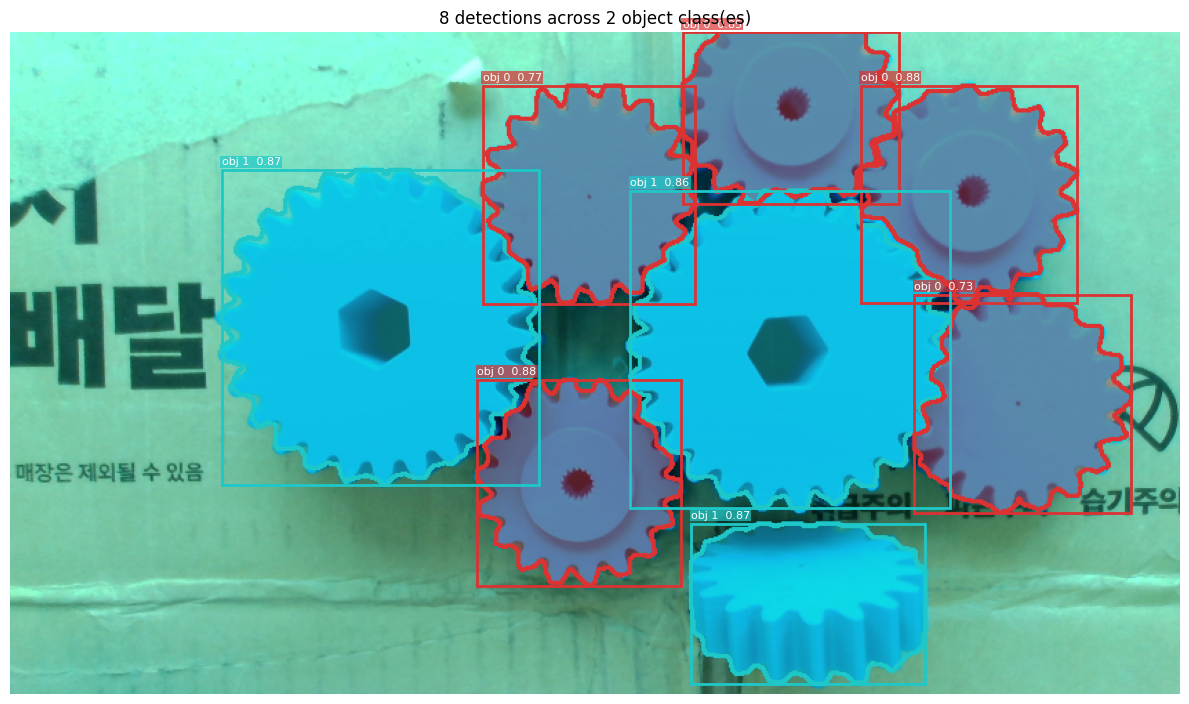

In [28]:
def visualize_detections(image, results, alpha=0.4):
    import cv2
    image_np = np.array(image)

    COLORS = [
        "#DC3232",  # red
        "#1EC8C8",  # cyan
        "#3264DC",  # blue
        "#32B432",  # green
        "#A032DC",  # purple
        "#F08C1E",  # orange
        "#1EC8C8",  # cyan
        "#E650B4",  # pink
        "#C8C828",  # yellow
    ]

    def hex_to_rgb(h):
        h = h.lstrip("#")
        return np.array([int(h[i:i+2], 16) for i in (0, 2, 4)])

    masks      = results["masks"].cpu().numpy()       # [N, H, W]
    boxes      = results["boxes"].cpu().numpy()       # [N, 4] xyxy
    object_ids = results["object_ids"].cpu().numpy()  # [N]
    scores     = results["scores"].cpu().numpy()      # [N]

    unique_ids = np.unique(object_ids)
    color_map  = {oid: hex_to_rgb(COLORS[i % len(COLORS)]) for i, oid in enumerate(unique_ids)}

    # Draw fills large-to-small so smaller detections appear on top at overlaps
    order   = np.argsort([-m.sum() for m in masks])
    overlay = image_np.copy().astype(float)
    for i in order:
        mask  = masks[i].astype(bool)
        color = color_map[object_ids[i]]
        overlay[mask] = (1 - alpha) * overlay[mask] + alpha * color

    canvas = overlay.astype(np.uint8)

    # Contours drawn last so boundaries are always crisp regardless of overlap
    for i in order:
        contours, _ = cv2.findContours(
            masks[i].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(canvas, contours, -1, color_map[object_ids[i]].tolist(), 2)

    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    ax.imshow(canvas)

    for box, oid, score in zip(boxes, object_ids, scores):
        x1, y1, x2, y2 = box
        color = color_map[oid] / 255.0
        rect  = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, y1 - 4, f"obj {oid}  {score:.2f}",
            color="white", fontsize=8,
            bbox=dict(facecolor=color, alpha=0.7, pad=1, edgecolor="none"),
        )

    ax.axis("off")
    ax.set_title(f"{len(scores)} detections across {len(np.unique(object_ids))} object class(es)")
    plt.tight_layout()
    plt.show()


visualize_detections(image, results)

## 5. Inspecting Score Distributions

`scores_per_object` gives the full score vector for each surviving detection — useful for analysis or thresholding beyond what NMS provides.

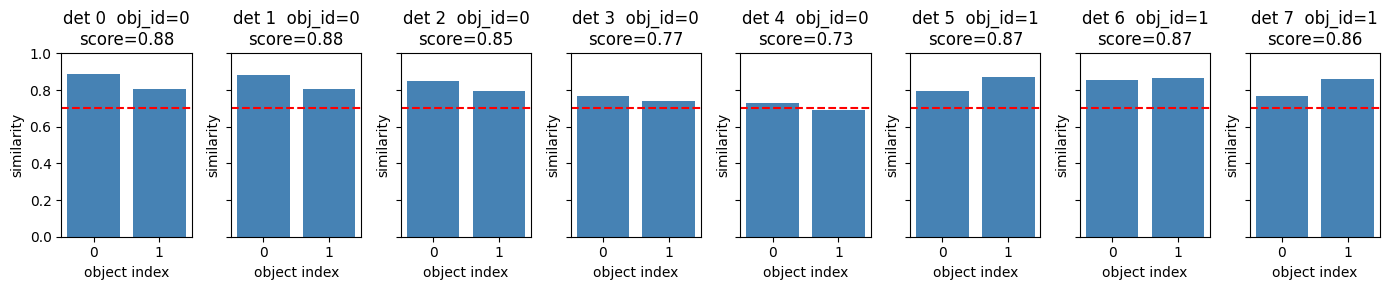

In [29]:
if len(results["scores"]) > 0:
    scores_per_object = results["scores_per_object"].cpu().numpy()  # [N, M]
    object_ids        = results["object_ids"].cpu().numpy()
    scores            = results["scores"].cpu().numpy()

    fig, axes = plt.subplots(1, min(8, len(scores)), figsize=(14, 3), sharey=True)
    if len(scores) == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        ax.bar(range(M), scores_per_object[i], color="steelblue")
        ax.axhline(cnos.confidence_threshold, color="red", linestyle="--", label="threshold")
        ax.set_title(f"det {i}  obj_id={object_ids[i]}\nscore={scores[i]:.2f}")
        ax.set_xlabel("object index")
        ax.set_ylabel("similarity")
        ax.set_xticks(range(M))
        ax.set_ylim(0, 1)

    # axes[0].legend()
    # plt.suptitle("Per-detection score distributions across all objects", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No detections to display.")

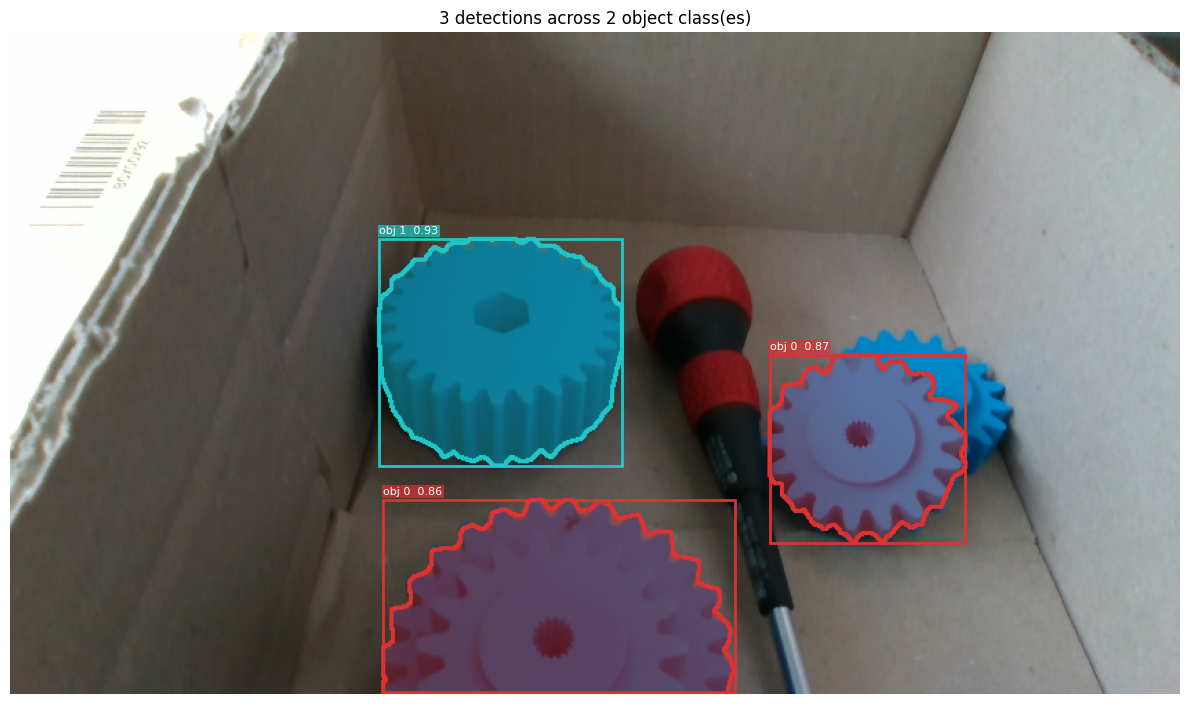

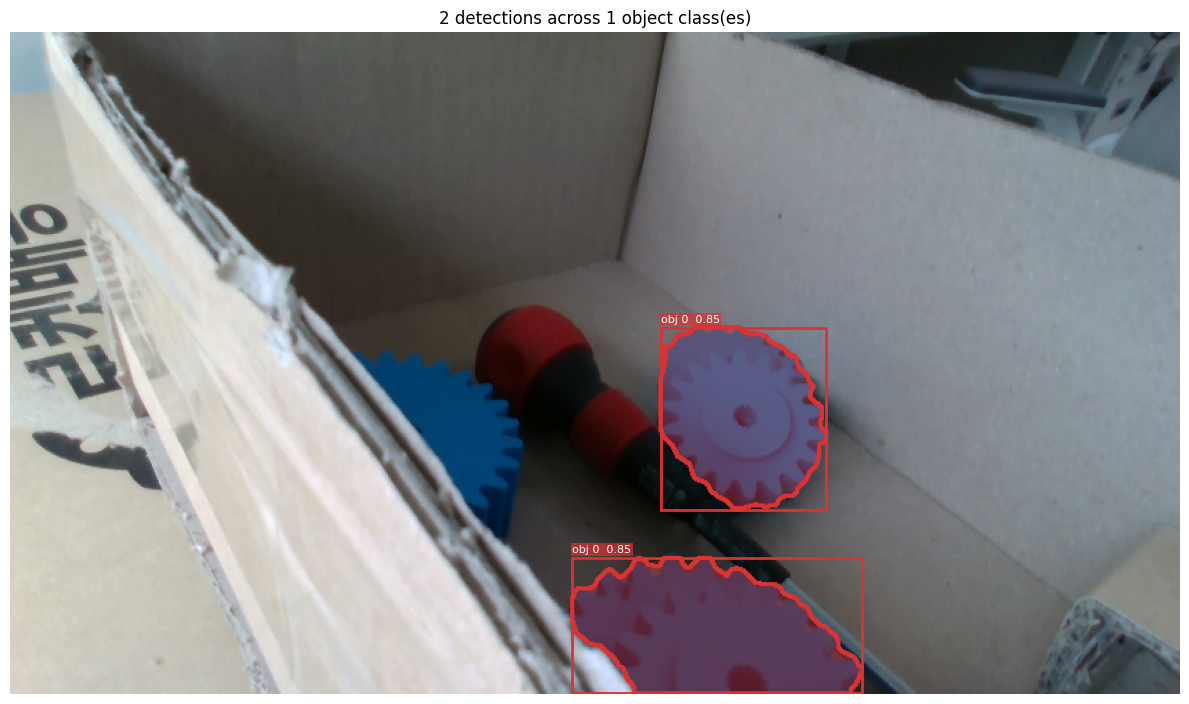

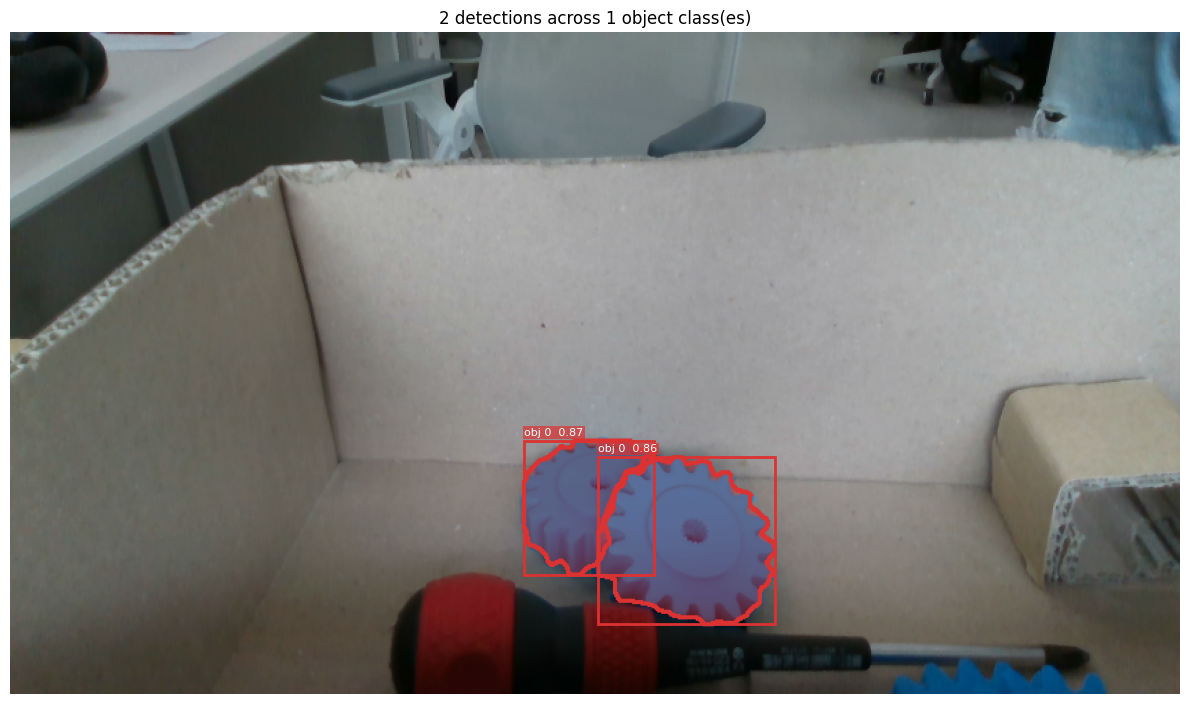

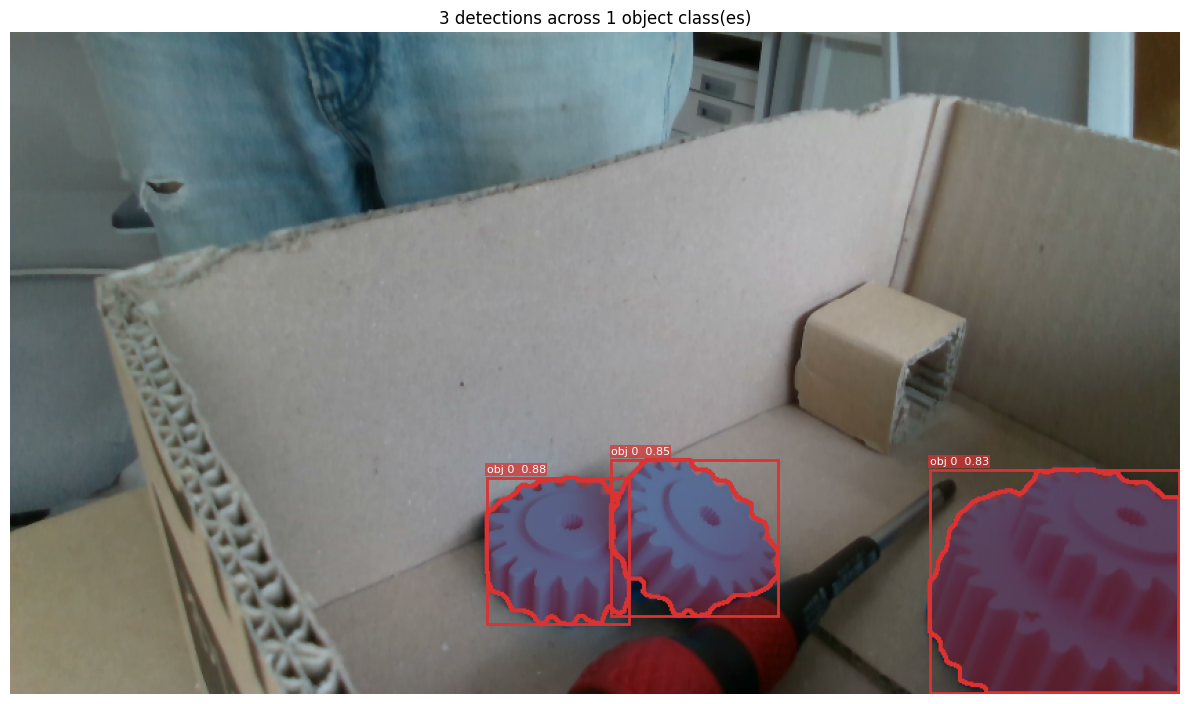

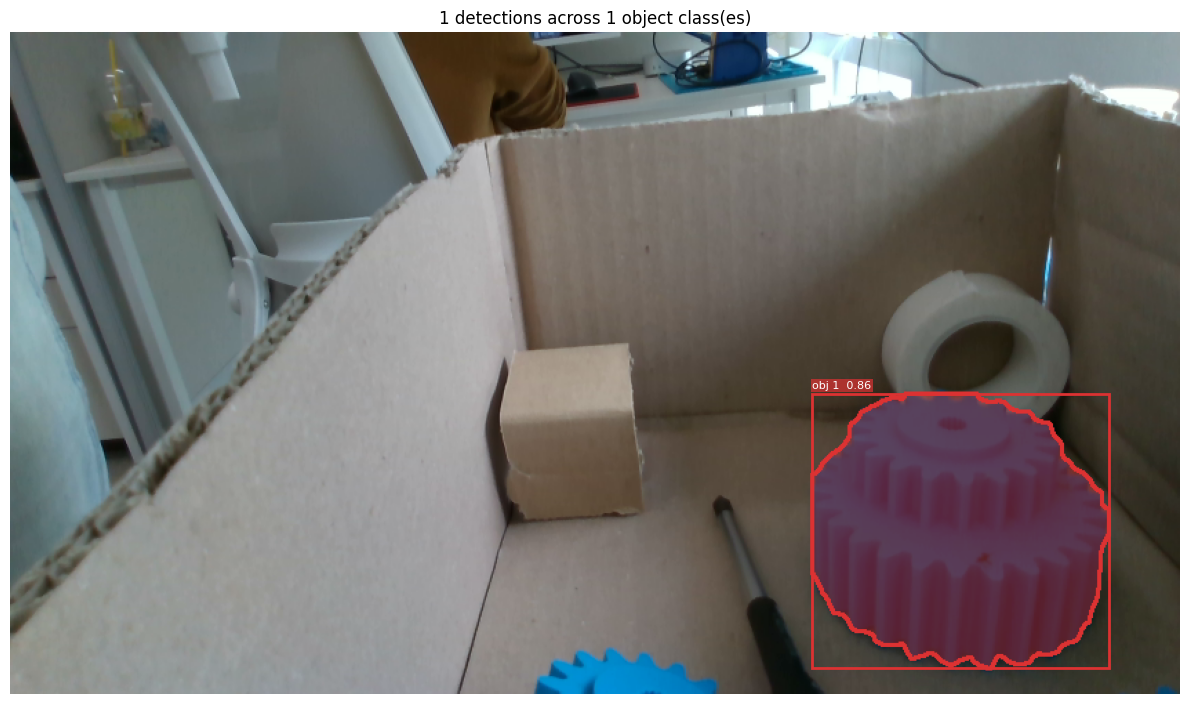

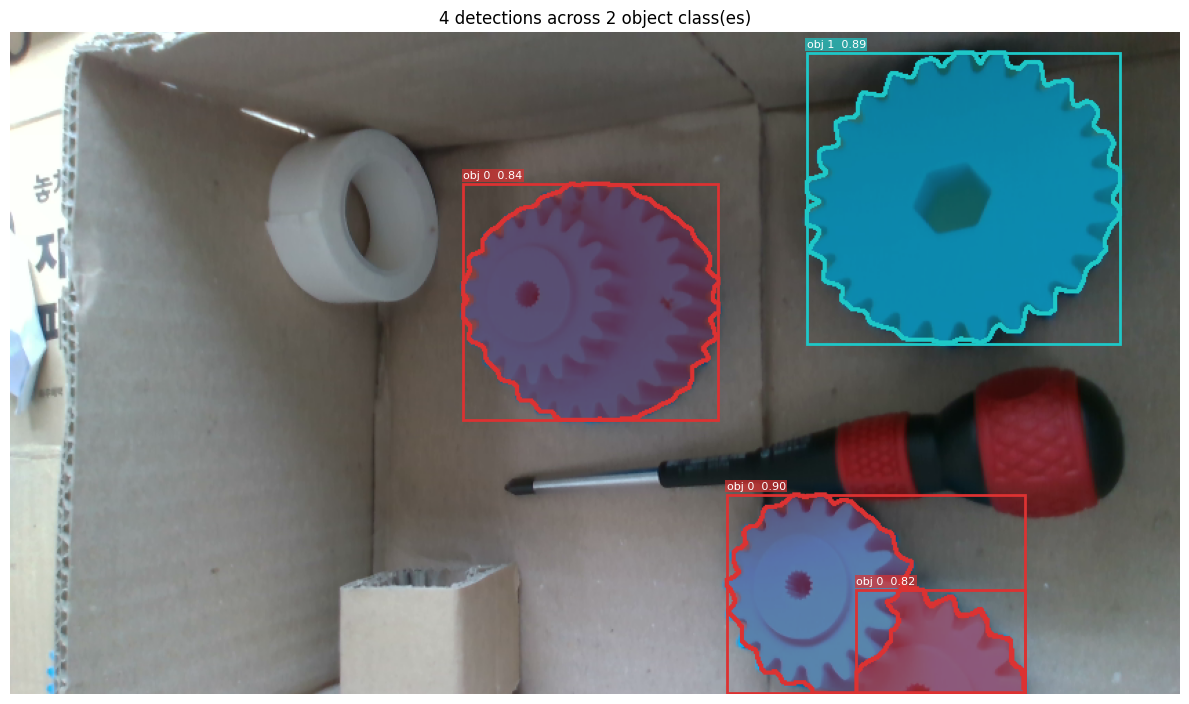

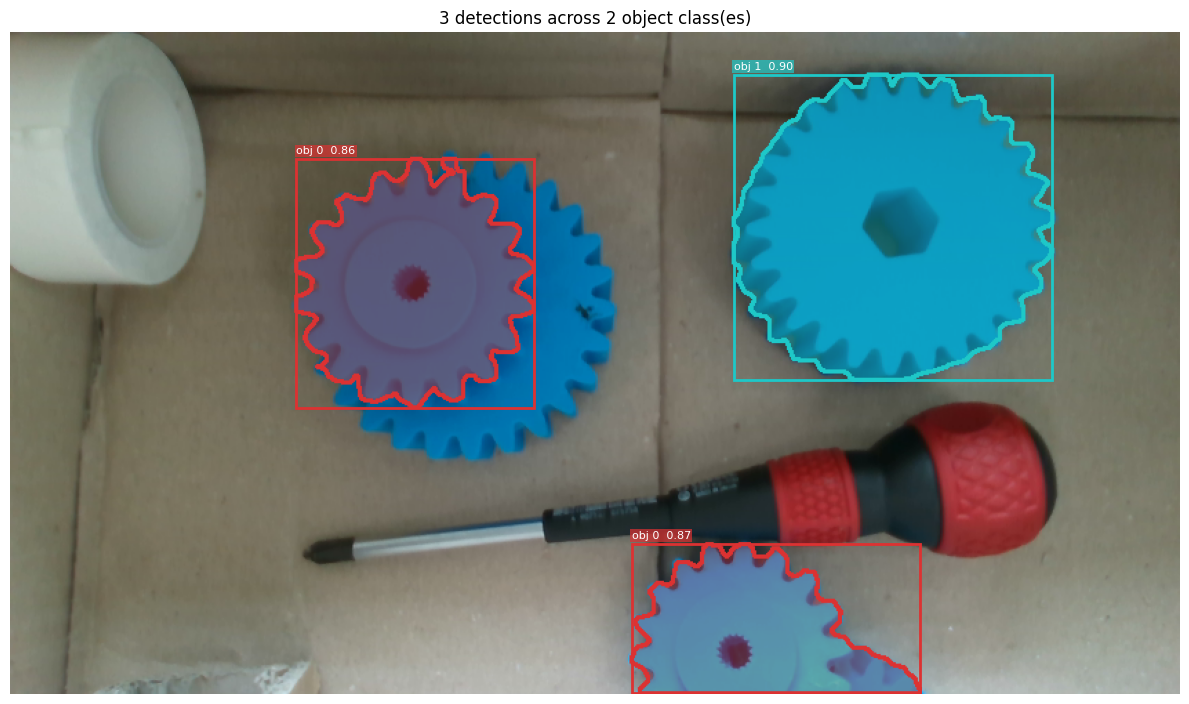

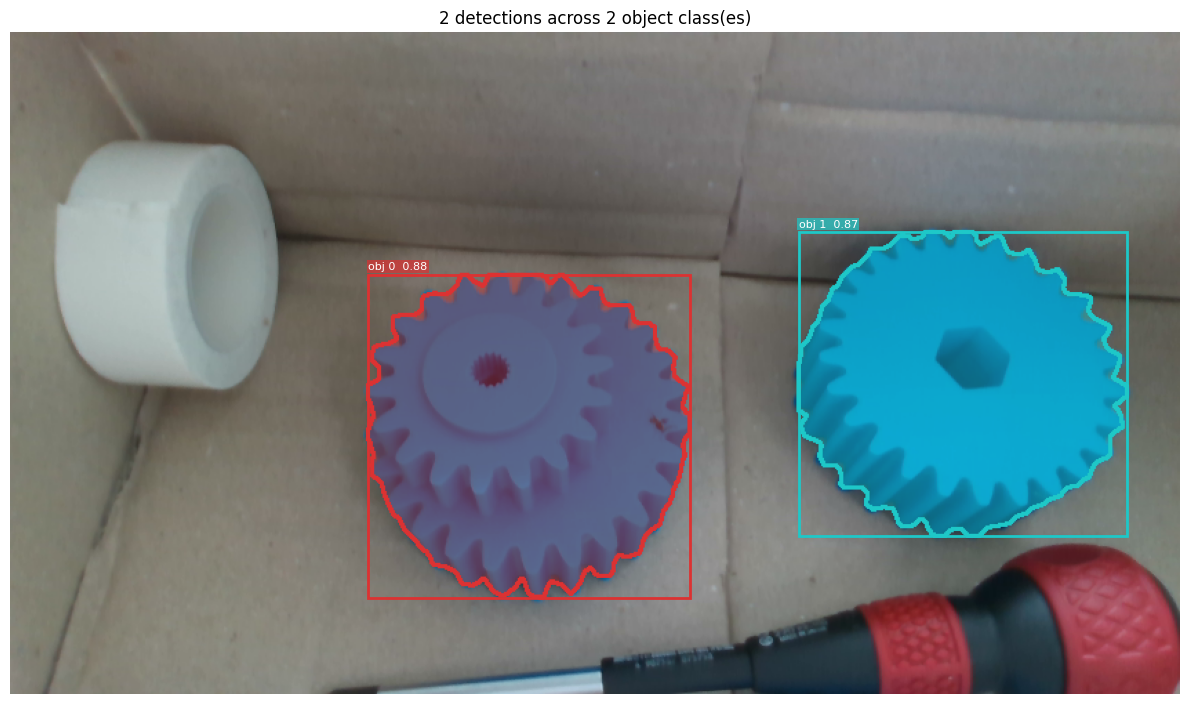

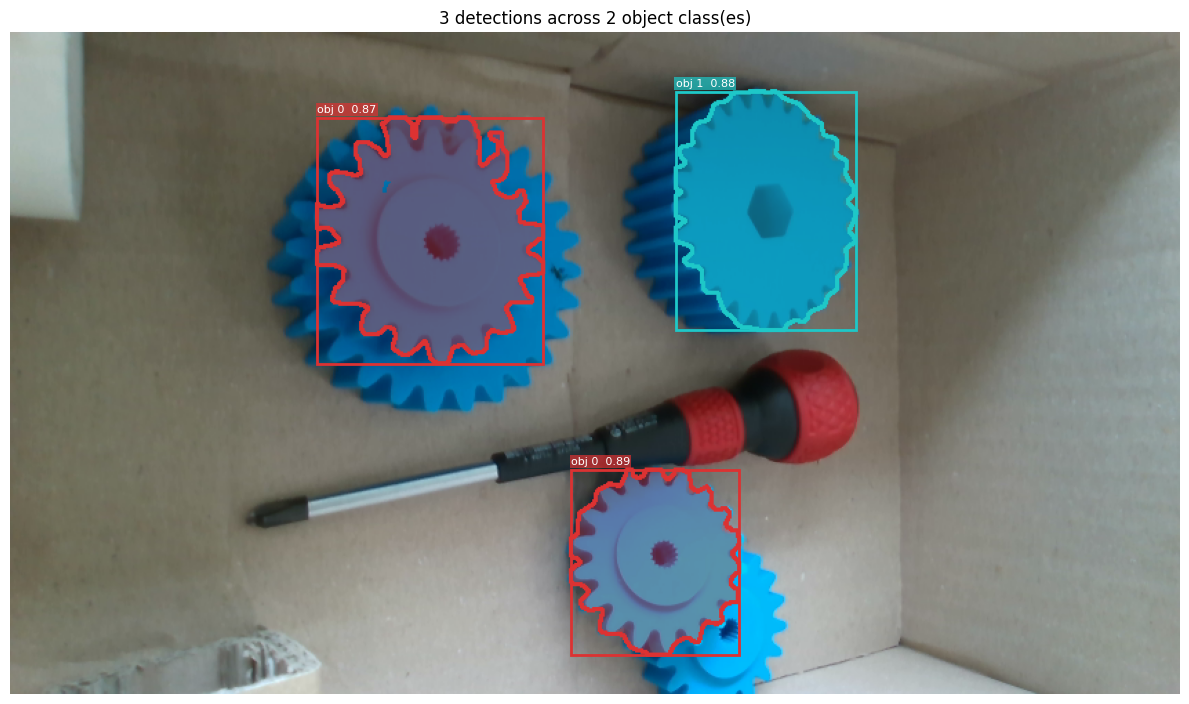

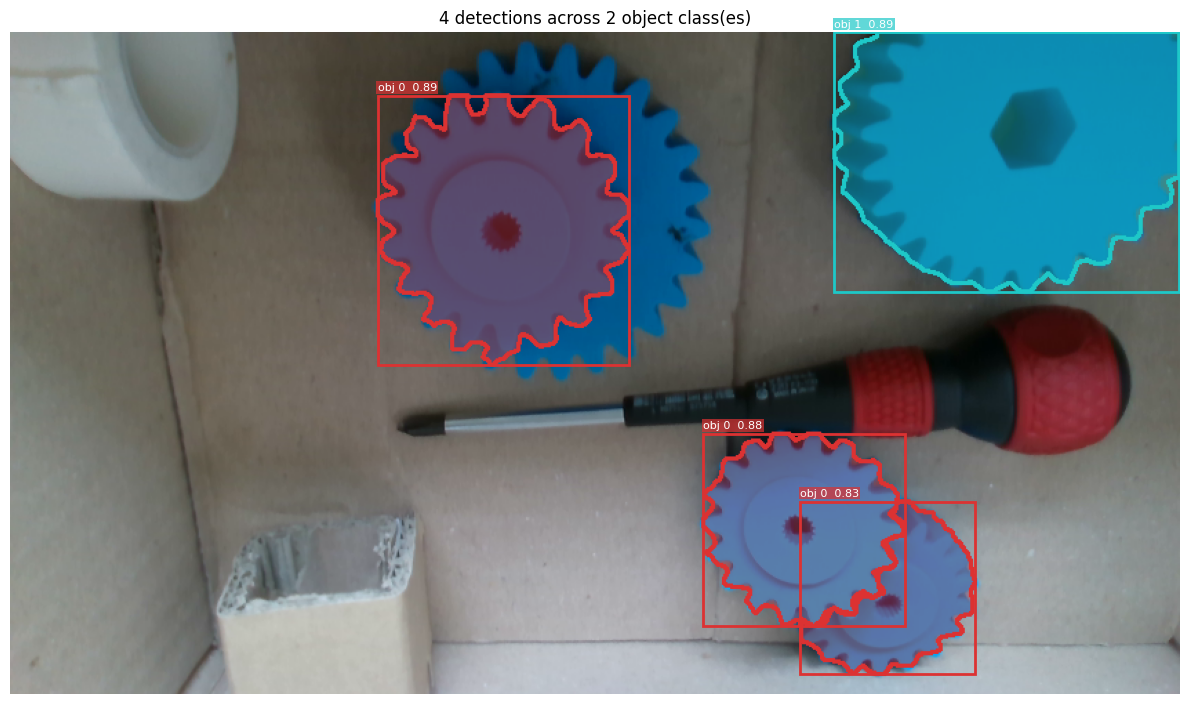

In [9]:
import pickle

# Load an object from a file
with open('/home/joon/Projects/robot-arm-motion-and-sensing-experiment/notebooks/data_cap_depth.pkl', 'rb') as file:
    loaded_data = pickle.load(file)

[captures, depth_predictions] = loaded_data

for t, (image, depth, DoF) in enumerate(captures):
    image = Image.fromarray(image)
    results = cnos(image)   # or cnos.forward(image)
    visualize_detections(image, results)